<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week11_Clustering_ex1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/Kor_Ramen_Export_Src.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1473 entries, 0 to 1472
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Year            1473 non-null   int64 
 1   ISO2C           1468 non-null   object
 2   balPayments     1473 non-null   int64 
 3   expDlr          1473 non-null   int64 
 4   expWgt          1473 non-null   int64 
 5   impWgt          1473 non-null   int64 
 6   impDlr          1473 non-null   int64 
 7   Import_Country  1473 non-null   object
 8   Exp_Item        1473 non-null   object
dtypes: int64(6), object(3)
memory usage: 103.7+ KB
None


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면
1,2015,AF,148,148,20,0,0,아프카니스탄,라면
2,2015,AO,322100,322100,84778,0,0,앙골라,라면
3,2015,AR,513384,513384,128065,0,0,아르헨티나,라면
4,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면
...,...,...,...,...,...,...,...,...,...
1468,2025,VU,181348,181348,46153,0,0,바누아투,라면
1469,2025,WS,2234923,2234923,447186,0,0,사모아,라면
1470,2025,ZA,6322340,6322340,1277895,0,0,남아프리카공화국,라면
1471,2025,ZM,177,177,168,0,0,잠비아,라면


### Data wrangling
  - 1. 2020년 기준으로 수출물량(expWgt)이 한해 10000kg 이상인 국가만을 대상
  - 2. 2020년 수출물량(expWgt)기준으로 추출된 대상국가들에 대해서 2015년부터 2025년까지 국가별로 수출물량의 비율 산출
  ( 예 ratio_expWgt_2020b = expWgt(2015) / expWgt(2020) )
  - 3. country_info 데이터셋과 결합(Merge or Join)를 통해서 df 데이터셋에 iso3c, name 컬럼 추가

#### 1.  2020년기준 expWgt >= 10000 이상인 국가추출

In [3]:
# 지수 표기법을 해제하고 소수점 아래 자릿수를 표현하도록 설정
pd.options.display.float_format = '{:.2f}'.format
df['expWgt'].describe()

,expWgt
count,1473.00
mean,1367817.07
std,5708436.35
min,0.00
25%,5574.00
50%,60933.00
75%,353023.00
max,108346661.00


In [4]:
# Filter df for year 2020 and expWgt >= 30000
target_list = df[(df['Year'] == 2020) & (df['expWgt'] >= 30000)][['Year', 'ISO2C', 'expWgt']]
target_list

,Year,ISO2C,expWgt
640,2020,AE,1196973
643,2020,AR,70291
644,2020,AS,225128
645,2020,AT,82973
646,2020,AU,6861871
...,...,...,...
766,2020,US,21824859
767,2020,UZ,152862
768,2020,VN,5252100
770,2020,WS,258229


  #### 2. 2020년 수출물량(expWgt)기준으로 2015년부터 2025년까지 국가별로 수출물량의 비율 산출 (예 ratio_expWgt_2020b = expWgt(2015) / expWgt(2020) )

In [5]:
# target_list에서 필요한 컬럼(ISO2C, expWgt)만 선택하고 컬럼명 변경
target_rename = target_list[['ISO2C', 'expWgt']].rename(columns={'expWgt': 'expWgt_2020b'})

# df와 target_rename을 ISO2C 기준으로 inner join 수행
df_joined = pd.merge(df, target_rename, on='ISO2C', how='inner')
print(df_joined.info())

# 결과 확인
display(df_joined)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Year            813 non-null    int64 
 1   ISO2C           813 non-null    object
 2   balPayments     813 non-null    int64 
 3   expDlr          813 non-null    int64 
 4   expWgt          813 non-null    int64 
 5   impWgt          813 non-null    int64 
 6   impDlr          813 non-null    int64 
 7   Import_Country  813 non-null    object
 8   Exp_Item        813 non-null    object
 9   expWgt_2020b    813 non-null    int64 
dtypes: int64(7), object(3)
memory usage: 63.6+ KB
None


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871
...,...,...,...,...,...,...,...,...,...,...
808,2025,US,254707684,254744425,51342782,1895,36741,미국,라면,21824859
809,2025,UZ,6448632,6475032,1569579,14165,26400,우즈베키스탄,라면,152862
810,2025,VN,23313522,26192394,6873710,590449,2878872,베트남,라면,5252100
811,2025,WS,2234923,2234923,447186,0,0,사모아,라면,258229


In [6]:
# expWgt / expWgt_2020b 비율 계산 및 결측치 0으로 처리
df_joined['ratio_expWgt_2020b'] = (df_joined['expWgt'] / df_joined['expWgt_2020b']).fillna(0)

# 결과 확인
df_joined

,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b,ratio_expWgt_2020b
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973,0.23
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291,1.82
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128,0.87
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973,0.01
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871,0.45
...,...,...,...,...,...,...,...,...,...,...,...
808,2025,US,254707684,254744425,51342782,1895,36741,미국,라면,21824859,2.35
809,2025,UZ,6448632,6475032,1569579,14165,26400,우즈베키스탄,라면,152862,10.27
810,2025,VN,23313522,26192394,6873710,590449,2878872,베트남,라면,5252100,1.31
811,2025,WS,2234923,2234923,447186,0,0,사모아,라면,258229,1.73


#### 3. country_info 데이터셋과 결합(Merge or Join)를 통해서 df 데이터셋에 iso3c, name 컬럼 추가

In [7]:
country_info=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/country_region.csv')
print(country_info.info())
country_info.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   name                      249 non-null    object 
 1   iso2c                     248 non-null    object 
 2   iso3c                     249 non-null    object 
 3   country-code              249 non-null    int64  
 4   iso_3166-2                249 non-null    object 
 5   region                    247 non-null    object 
 6   sub_region                247 non-null    object 
 7   intermediate_region       105 non-null    object 
 8   region_code               247 non-null    float64
 9   sub_region_code           247 non-null    float64
 10  intermediate_region_code  105 non-null    float64
dtypes: float64(3), int64(1), object(7)
memory usage: 21.5+ KB
None


,name,iso2c,iso3c,country-code,iso_3166-2,region,sub_region,intermediate_region,region_code,sub_region_code,intermediate_region_code
0,Afghanistan,AF,AFG,4,ISO 3166-2:AF,Asia,Southern Asia,NaN,142.00,34.00,NaN
1,Islands,AX,ALA,248,ISO 3166-2:AX,Europe,Northern Europe,NaN,150.00,154.00,NaN
2,Albania,AL,ALB,8,ISO 3166-2:AL,Europe,Southern Europe,NaN,150.00,39.00,NaN
3,Algeria,DZ,DZA,12,ISO 3166-2:DZ,Africa,Northern Africa,NaN,2.00,15.00,NaN
4,American Samoa,AS,ASM,16,ISO 3166-2:AS,Oceania,Polynesia,NaN,9.00,61.00,NaN


In [8]:
# df_joined와 country_info에서 필요한 컬럼만 병합
df_joined = pd.merge(
    df_joined,
    country_info[['iso2c', 'iso3c', 'name']],
    left_on='ISO2C',
    right_on='iso2c',
    how='inner'
).drop(columns=['iso2c'])

# 결과 확인
display(df_joined.head())

,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b,ratio_expWgt_2020b,iso3c,name
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973,0.23,ARE,United Arab Emirates
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291,1.82,ARG,Argentina
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128,0.87,ASM,American Samoa
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973,0.01,AUT,Austria
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871,0.45,AUS,Australia


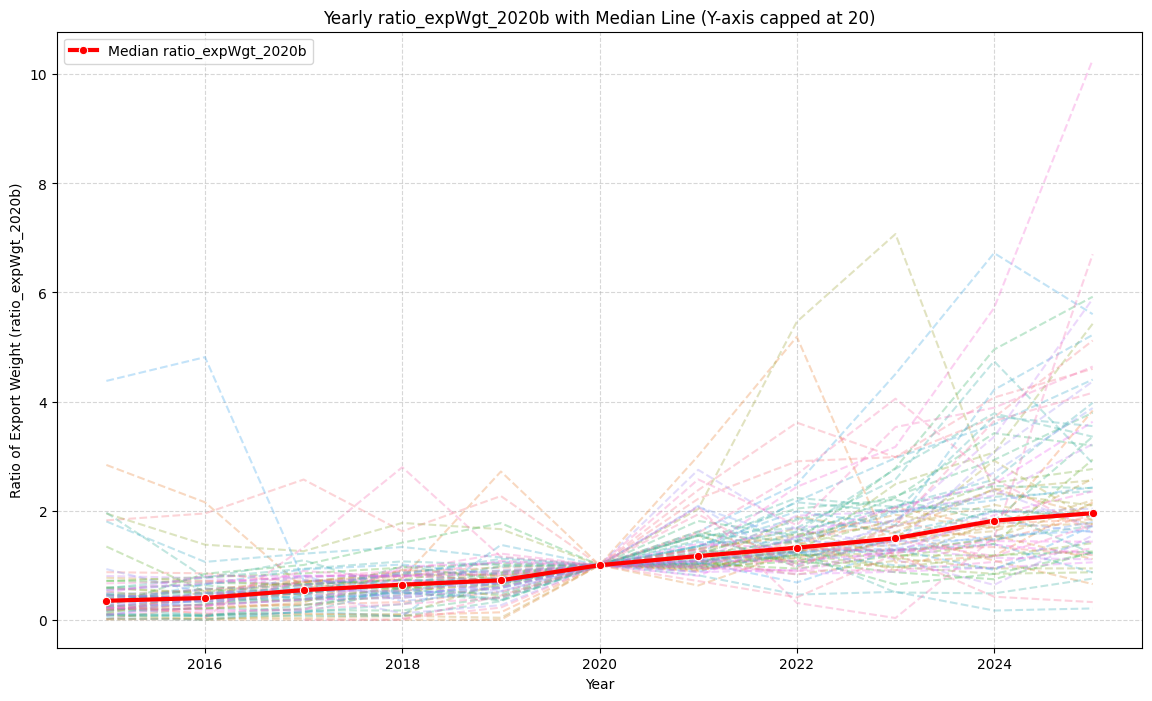

In [9]:
# 연도별 중앙값 계산
median_by_year = df_joined.groupby('Year')['ratio_expWgt_2020b'].median().reset_index()

# 시각화
plt.figure(figsize=(14, 8))

# 각 국가별 추이 선그래프 (구분을 위해 개별 데이터 플롯)
sns.lineplot(data=df_joined, x='Year', y='ratio_expWgt_2020b', hue='name', legend=False, alpha=0.3, linestyle="--")

# 연도별 중앙값 강조 선그래프
sns.lineplot(data=median_by_year, x='Year', y='ratio_expWgt_2020b', color='red', linewidth=3, marker='o', label='Median ratio_expWgt_2020b')

# Y축 상한선을 20으로 설정
#plt.ylim(0, 20)

plt.title('Yearly ratio_expWgt_2020b with Median Line (Y-axis capped at 20)')
plt.xlabel('Year')
plt.ylabel('Ratio of Export Weight (ratio_expWgt_2020b)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [10]:
# iso3c, name을 인덱스로 하고, Year를 컬럼으로 하여 ratio_expWgt_2020b 값을 피벗(전치)
pivoted_df = df_joined.pivot_table(
    index=['iso3c', 'name'],
    columns='Year',
    values='ratio_expWgt_2020b',
    aggfunc='first'  # 연도별 국가 데이터가 유일하므로 'first' 사용
).reset_index()

# 결과 확인
pivoted_df.info()
display(pivoted_df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   iso3c   75 non-null     object 
 1   name    75 non-null     object 
 2   2015    71 non-null     float64
 3   2016    72 non-null     float64
 4   2017    72 non-null     float64
 5   2018    74 non-null     float64
 6   2019    74 non-null     float64
 7   2020    75 non-null     float64
 8   2021    75 non-null     float64
 9   2022    75 non-null     float64
 10  2023    75 non-null     float64
 11  2024    75 non-null     float64
 12  2025    75 non-null     float64
dtypes: float64(11), object(2)
memory usage: 7.7+ KB


Year,iso3c,name,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,ARE,United Arab Emirates,0.23,0.40,0.69,0.65,0.77,1.00,2.38,3.61,2.98,4.07,4.60
1,ARG,Argentina,1.82,1.95,2.57,1.62,2.27,1.00,2.22,2.90,2.98,3.71,5.12
2,ASM,American Samoa,0.87,0.85,0.69,0.89,0.95,1.00,1.03,1.27,1.29,1.33,1.18
3,AUS,Australia,0.45,0.55,0.69,0.82,0.90,1.00,0.91,1.14,1.45,1.76,1.84
4,AUT,Austria,0.01,0.25,0.28,0.32,0.51,1.00,1.13,1.45,1.81,1.44,1.92
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,USA,United States of America,0.36,0.45,0.54,0.64,0.68,1.00,1.01,0.88,1.25,1.92,2.35
71,UZB,Uzbekistan,0.22,0.26,0.37,0.40,0.59,1.00,1.22,2.44,3.17,5.72,10.27
72,VNM,Viet Nam,0.18,0.40,0.89,0.77,1.08,1.00,0.95,0.90,0.91,1.06,1.31
73,WSM,Samoa,0.67,0.71,0.76,0.90,1.21,1.00,1.28,1.01,1.46,1.17,1.73


- 결측값(missing value) 처리

In [12]:
pivoted_df.isnull().sum()

,0
Year,
iso3c,0
name,0
2015,4
2016,3
2017,3
2018,1
2019,1
2020,0
2021,0


In [13]:
# pivoted_df의 모든 결측값(NaN)을 0으로 처리
pivoted_df = pivoted_df.fillna(0)

# 결측치 처리 결과 확인
print("--- 결측치 처리 후 개수 ---")
print(pivoted_df.isnull().sum())

--- 결측치 처리 후 개수 ---
Year
iso3c    0
name     0
2015     0
2016     0
2017     0
2018     0
2019     0
2020     0
2021     0
2022     0
2023     0
2024     0
2025     0
dtype: int64


## 2020년기준 수출물량비율 추이별 군집화(Clustering)

In [14]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("K-Means 클러스터링 분석 시작")
print("=" * 80)

K-Means 클러스터링 분석 시작


In [15]:
# ============================================================================
# 1단계: 데이터 로드 및 탐색
# ============================================================================
print("\n[1단계] 데이터 로드 및 탐색")
print("-" * 80)

print("데이터 shape:", pivoted_df.shape)
print("\n처음 5행:")
print(pivoted_df.head())
print("\n컬럼 정보:")
print(pivoted_df.info())
print("\n결측치 확인:")
print(pivoted_df.isnull().sum())


[1단계] 데이터 로드 및 탐색
--------------------------------------------------------------------------------
데이터 shape: (75, 13)

처음 5행:
Year iso3c                  name  2015  2016  2017  2018  2019  2020  2021  \
0      ARE  United Arab Emirates  0.23  0.40  0.69  0.65  0.77  1.00  2.38   
1      ARG             Argentina  1.82  1.95  2.57  1.62  2.27  1.00  2.22   
2      ASM        American Samoa  0.87  0.85  0.69  0.89  0.95  1.00  1.03   
3      AUS             Australia  0.45  0.55  0.69  0.82  0.90  1.00  0.91   
4      AUT               Austria  0.01  0.25  0.28  0.32  0.51  1.00  1.13   

Year  2022  2023  2024  2025  
0     3.61  2.98  4.07  4.60  
1     2.90  2.98  3.71  5.12  
2     1.27  1.29  1.33  1.18  
3     1.14  1.45  1.76  1.84  
4     1.45  1.81  1.44  1.92  

컬럼 정보:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   iso3c   75 non-null     obj

In [16]:
# ============================================================================
# 2단계: 데이터 전처리
# ============================================================================
print("\n[2단계] 데이터 전처리")
print("-" * 80)

# pivoted_df의 컬럼이 정수형이므로, 정수형 리스트로 선택 (2015~2025)
year_columns = list(range(2016, 2026))
print(f"사용할 컬럼: {year_columns}")

# 숫자 데이터만 선택
df_clustering = pivoted_df[year_columns].copy()

# 결측치 처리 (0으로 채우기)
df_clustering = df_clustering.fillna(0)

print(f"클러스터링 데이터 shape: {df_clustering.shape}")
print(f"결측치 처리 완료")


[2단계] 데이터 전처리
--------------------------------------------------------------------------------
사용할 컬럼: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
클러스터링 데이터 shape: (75, 10)
결측치 처리 완료


In [34]:
# ============================================================================
# 3단계: 데이터 정규화
# ============================================================================
print("\n[3단계] 데이터 정규화")
print("-" * 80)

#scaler = StandardScaler()
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_clustering)

print(f"정규화 완료. Shape: {df_scaled.shape}")

# numpy.ndarray를 Pandas DataFrame으로 변환하여 요약 통계 확인
pd.DataFrame(df_scaled, columns=df_clustering.columns).describe().T


[3단계] 데이터 정규화
--------------------------------------------------------------------------------
정규화 완료. Shape: (75, 10)


,count,mean,std,min,25%,50%,75%,max
Year,,,,,,,,
2016,75.00,0.11,0.13,0.00,0.05,0.08,0.13,1.00
2017,75.00,0.21,0.15,0.00,0.13,0.21,0.27,1.00
2018,75.00,0.23,0.15,0.00,0.16,0.23,0.29,1.00
2019,75.00,0.28,0.16,0.00,0.21,0.26,0.33,1.00
2020,75.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2021,75.00,0.29,0.20,0.00,0.16,0.23,0.37,1.00
2022,75.00,0.24,0.16,0.00,0.16,0.20,0.27,1.00
2023,75.00,0.25,0.14,0.00,0.17,0.21,0.29,1.00
2024,75.00,0.30,0.19,0.00,0.18,0.25,0.38,1.00



[4단계] 최적의 K 값 찾기 (Elbow Method & Silhouette Score)
--------------------------------------------------------------------------------
K=2: Inertia=13.13, Silhouette=0.363
K=3: Inertia=10.51, Silhouette=0.362
K=4: Inertia=9.33, Silhouette=0.251
K=5: Inertia=8.22, Silhouette=0.267
K=6: Inertia=7.22, Silhouette=0.258
K=7: Inertia=6.41, Silhouette=0.269
K=8: Inertia=5.79, Silhouette=0.239
K=9: Inertia=4.99, Silhouette=0.223
K=10: Inertia=4.51, Silhouette=0.201


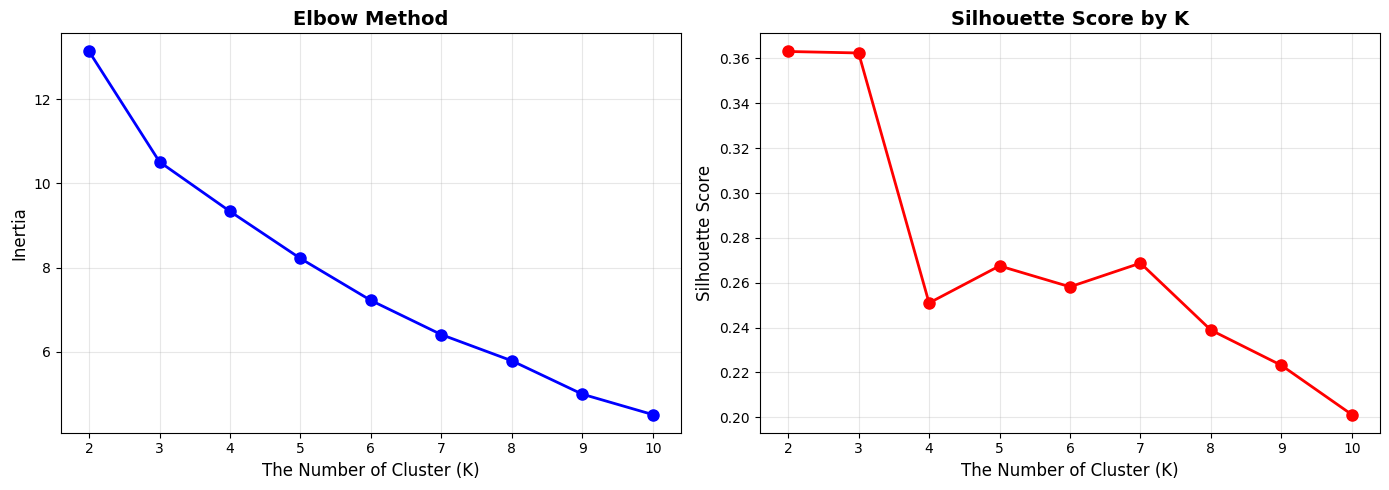


✓ Silhouette Score 기준 최적 K: 2


In [35]:
# ============================================================================
# 4단계: 최적의 K 값 찾기
# ============================================================================
print("\n[4단계] 최적의 K 값 찾기 (Elbow Method & Silhouette Score)")
print("-" * 80)

inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))
    print(f"K={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={silhouette_scores[-1]:.3f}")

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('The Number of Cluster (K)', fontsize=12)
axes[0].set_ylabel('Inertia', fontsize=12)
axes[0].set_title('Elbow Method', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Silhouette Score
axes[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_xlabel('The Number of Cluster (K)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Score by K', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('01_optimal_k_selection.png', dpi=300, bbox_inches='tight')
plt.show()

optimal_k = K_range[np.argmax(silhouette_scores)]
print(f"\n✓ Silhouette Score 기준 최적 K: {optimal_k}")

In [36]:
# ============================================================================
# 5단계: K-Means 클러스터링 실행
# ============================================================================
print(f"\n[5단계] K-Means 클러스터링 실행 (K={optimal_k})")
print("-" * 80)

num_clusters = 8
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)

clusters = kmeans.fit_predict(df_scaled)

# 원래의 1473행을 가진 df 대신, 92행인 pivoted_df에 Cluster 컬럼을 추가합니다.
pivoted_df['Cluster'] = clusters

print(f"클러스터링 완료!")
print(f"\n클러스터별 개수:")
print(pivoted_df['Cluster'].value_counts().sort_index())


[5단계] K-Means 클러스터링 실행 (K=2)
--------------------------------------------------------------------------------
클러스터링 완료!

클러스터별 개수:
Cluster
0    36
1     9
2     1
3     3
4     3
5    17
6     1
7     5
Name: count, dtype: int64


In [37]:
# ============================================================================
# 6단계: 클러스터링 결과 분석
# ============================================================================
print(f"\n[6단계] 클러스터링 결과 분석")
print("-" * 80)

# df 대신 클러스터링 컬럼이 들어있는 pivoted_df를 사용합니다.
cluster_summary = pivoted_df.groupby('Cluster')[year_columns].mean()
print("\n클러스터별 연도별 평균값:")
print(cluster_summary.round(2))

if 'name' in pivoted_df.columns:
    print("\n클러스터별 국가/지역:")
    # K-Means를 num_clusters 개 클러스터로 학습했으므로 8개 클러스터를 순회합니다.
    for cluster in range(num_clusters):
        print(f"\n=== 클러스터 {cluster} ({len(pivoted_df[pivoted_df['Cluster'] == cluster])}개) ===")
        countries = pivoted_df[pivoted_df['Cluster'] == cluster]['name'].values
        print(', '.join(countries))


[6단계] 클러스터링 결과 분석
--------------------------------------------------------------------------------

클러스터별 연도별 평균값:
Year     2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
Cluster                                                            
0        0.65  0.66  0.77  0.85  1.00  1.08  1.26  1.32  1.53  1.71
1        0.43  0.51  0.65  0.82  1.00  1.27  1.89  2.70  4.53  5.23
2        2.15  0.58  0.76  2.72  1.00  3.00  5.19  1.05  1.17  2.15
3        0.34  0.46  0.35  0.48  1.00  2.57  2.33  2.63  3.68  4.54
4        1.12  1.72  2.06  1.70  1.00  1.97  1.47  1.83  2.76  5.75
5        0.21  0.27  0.33  0.50  1.00  1.48  1.53  2.02  2.39  2.83
6        0.00  0.09  0.10  0.67  1.00  2.03  5.46  7.07  2.32  2.09
7        0.15  0.19  0.31  0.30  1.00  0.83  0.92  0.96  0.60  0.56

클러스터별 국가/지역:

=== 클러스터 0 (36개) ===
American Samoa, Australia, Bahrain, Brazil, Brunei Darussalam, Canada, Switzerland, Chile, China, Dominican Republic, Micronesia, Federated States of, United Kingdom of


[7단계] PCA를 이용한 2D 시각화
--------------------------------------------------------------------------------
PCA 설명된 분산 비율:
  PC1: 0.377 (37.7%)
  PC2: 0.264 (26.4%)
  총합: 0.782 (78.2%)


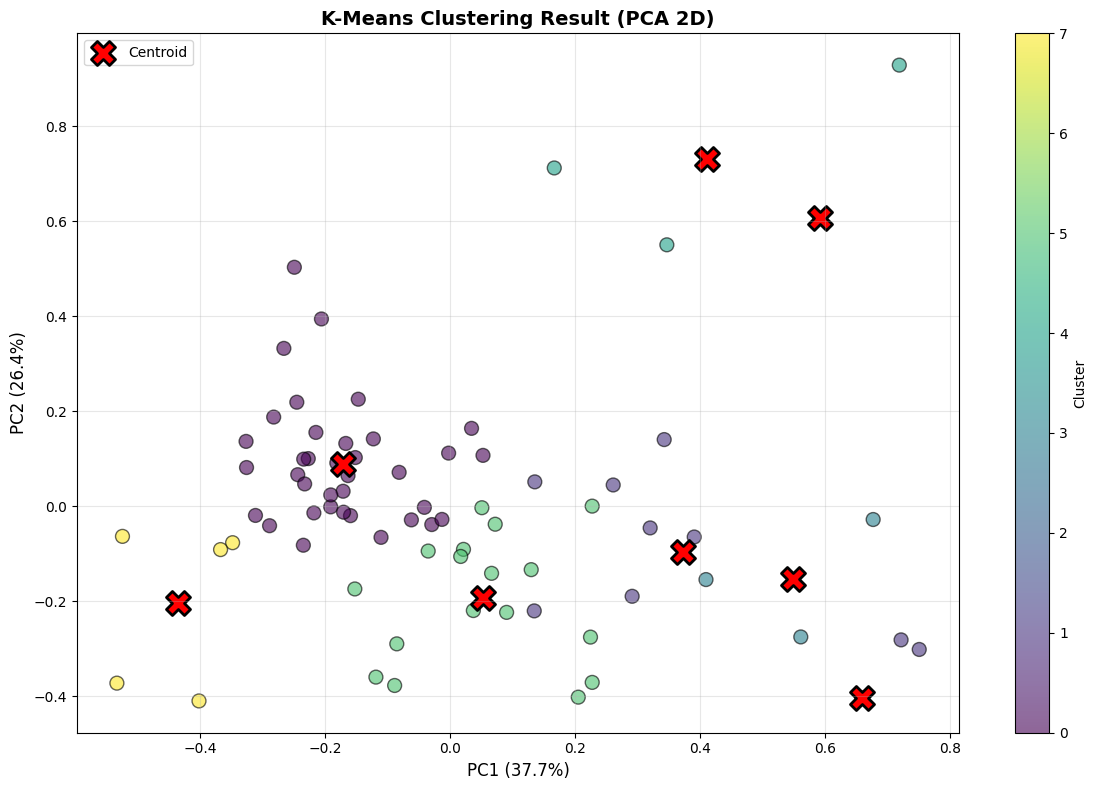

In [38]:
# ============================================================================
# 7단계: PCA를 이용한 2D 시각화
# ============================================================================
print(f"\n[7단계] PCA를 이용한 2D 시각화")
print("-" * 80)

pca = PCA(n_components=3, random_state=42)
df_pca = pca.fit_transform(df_scaled)

print(f"PCA 설명된 분산 비율:")
print(f"  PC1: {pca.explained_variance_ratio_[0]:.3f} ({pca.explained_variance_ratio_[0]*100:.1f}%)")
print(f"  PC2: {pca.explained_variance_ratio_[1]:.3f} ({pca.explained_variance_ratio_[1]*100:.1f}%)")
print(f"  총합: {sum(pca.explained_variance_ratio_):.3f} ({sum(pca.explained_variance_ratio_)*100:.1f}%)")

plt.figure(figsize=(12, 8))
scatter = plt.scatter(df_pca[:, 0], df_pca[:, 1],
                     c=clusters, cmap='viridis',
                     s=100, alpha=0.6, edgecolors='black', linewidth=1)

centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1],
           c='red', marker='X', s=300, edgecolors='black', linewidth=2,
           label='Centroid')

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title('K-Means Clustering Result (PCA 2D)', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('02_pca_clustering_visualization.png', dpi=300, bbox_inches='tight')
plt.show()


[8단계] 클러스터별 시계열 패턴 시각화 (개별 subplot)
--------------------------------------------------------------------------------


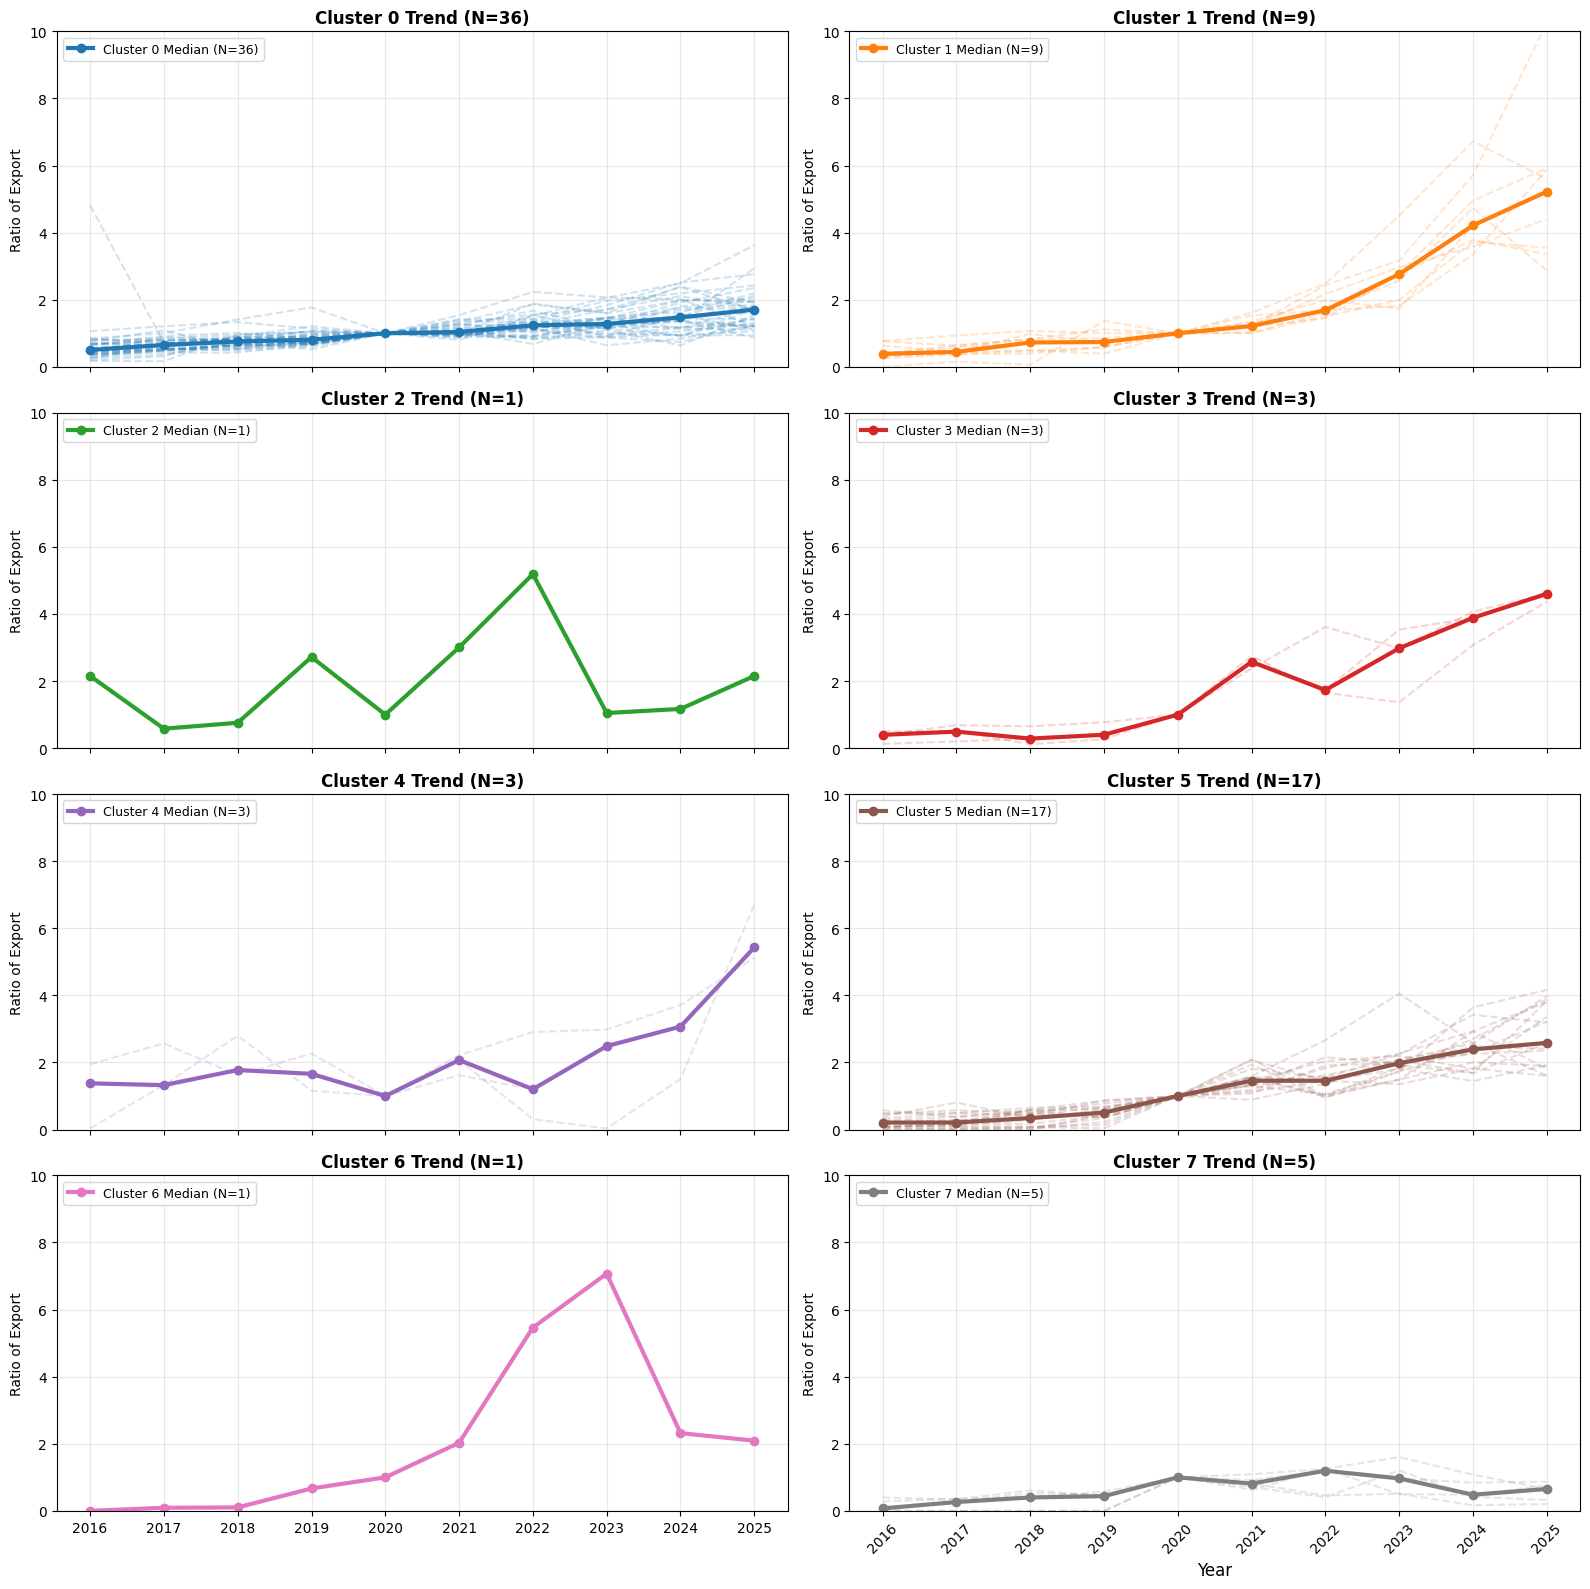

In [39]:
# ============================================================================
# 8단계: 클러스터별 시계열 패턴 개별 시각화 (Subplots)
# ============================================================================
print(f"\n[8단계] 클러스터별 시계열 패턴 시각화 (개별 subplot)")
print("-" * 80)

# 현재 정의된 실제 클러스터 개수 (num_clusters = 8)
n_rows = int(np.ceil(num_clusters / 2))  # 2열로 배치하기 위한 행 수 계산

fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4 * n_rows), sharex=True)
axes = axes.flatten()  # 2차원 배열을 1차원으로 평탄화하여 쉽게 인덱싱

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']

for cluster in range(num_clusters):
    ax = axes[cluster]
    # 해당 클러스터에 속하는 국가들의 데이터 필터링
    cluster_df = pivoted_df[pivoted_df['Cluster'] == cluster]

    # 클러스터 내 국가 수
    n_countries = len(cluster_df)

    # 각 국가들의 개별 추이 (연한 선으로 표시)
    for _, row in cluster_df.iterrows():
        ax.plot(year_columns, row[year_columns], color=colors[cluster % len(colors)], alpha=0.2, linestyle='--')

    # 클러스터의 중앙값(Median) 계산 및 시각화 (굵은 선)
    cluster_median = cluster_df[year_columns].median()
    ax.plot(year_columns, cluster_median, marker='o', linewidth=3,
            markersize=6, color=colors[cluster % len(colors)],
            label=f'Cluster {cluster} Median (N={n_countries})')

    ax.set_title(f'Cluster {cluster} Trend (N={n_countries})', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ratio of Export')
    # Y축 범위를 0에서 10으로 고정
    ax.set_ylim(0, 10)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left', fontsize=9)

# 사용하지 않는 나머지 서브플롯은 숨기기
for i in range(num_clusters, len(axes)):
    fig.delaxes(axes[i])

plt.xlabel('Year', fontsize=12)
plt.xticks(year_columns, rotation=45)
plt.tight_layout()
plt.savefig('03_cluster_timeseries_subplots.png', dpi=300, bbox_inches='tight')
plt.show()